# Modeling recorded arrest status

This notebook compares a no-arrest reference, logistic regression, a decision tree, K-nearest neighbors, and a small neural network. The target is the arrest status recorded in this copy of the data, not whether an arrest will happen later.

The test period stays separate until the final comparison. Model thresholds are selected on a validation sample with a minimum precision target of 0.25. This is a classroom comparison, not a deployment recommendation.

In [1]:
# load tools for comparing recorded arrest patterns
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# use the same scoring tools across the candidate models
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.metrics import precision_score, recall_score
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

# keep the random seeds fixed for repeat runs
random.seed(42)
tf.random.set_seed(42)
np.random.seed(42)

## Load the prepared data

The occurrence date is metadata for sorting. It is not included in the predictors.

In [2]:
# check the saved inputs before comparing models across periods
train_df = pd.read_parquet('../data/model_train_time_split.parquet')
test_df = pd.read_parquet('../data/model_test_time_split.parquet')
assert 'DATE OCC' in train_df.columns, 'Training dates are required'
assert train_df.columns.equals(test_df.columns), 'Mismatched columns'
assert not train_df.isnull().any().any(), 'Missing training values'
assert not test_df.isnull().any().any(), 'Missing test values'

In [3]:
# sort by occurrence date so later rows can be held out
train_df['DATE OCC'] = pd.to_datetime(train_df['DATE OCC'], errors='raise')
test_df['DATE OCC'] = pd.to_datetime(test_df['DATE OCC'], errors='raise')
train_df = train_df.sort_values('DATE OCC').reset_index(drop=True)
test_df = test_df.sort_values('DATE OCC').reset_index(drop=True)
assert train_df['DATE OCC'].max() < test_df['DATE OCC'].min()
print(f'Train dates: {train_df["DATE OCC"].min()} to {train_df["DATE OCC"].max()}')
print(f'Test dates: {test_df["DATE OCC"].min()} to {test_df["DATE OCC"].max()}')

Train dates: 2010-01-01 00:00:00 to 2019-12-31 00:00:00
Test dates: 2020-01-01 00:00:00 to 2024-02-29 00:00:00


In [4]:
# keep the outcome and date metadata out of the predictors
X_train = train_df.drop(['Arrested', 'DATE OCC'], axis=1)
X_test = test_df.drop(['Arrested', 'DATE OCC'], axis=1)
y_train = train_df['Arrested'].astype(int)
y_test = test_df['Arrested'].astype(int)
assert X_train.columns.equals(X_test.columns)
assert set(y_train.unique()) == {0, 1}
assert set(y_test.unique()) == {0, 1}
print(f'Predictors: {X_train.shape[1]}')

Predictors: 73


## Make chronological fit and validation sets

The training rows are sorted by occurrence date before splitting. The earliest 80% is used to fit models and the latest 20% to select thresholds. Random samples from validation and test keep the more expensive comparisons manageable.

In [5]:
# reserve the latest training rows for validation, not fitting
split_index = int(len(X_train) * 0.8)
X_fit = X_train.iloc[:split_index]
X_val = X_train.iloc[split_index:]
y_fit = y_train.iloc[:split_index]
y_val = y_train.iloc[split_index:]
X_val_sample = X_val.sample(n=min(20000, len(X_val)), random_state=42)
y_val_sample = y_val.loc[X_val_sample.index]

In [6]:
# use one held-out sample for every model to make scores comparable
X_test_sample = X_test.sample(n=min(50000, len(X_test)), random_state=42)
y_test_sample = y_test.loc[X_test_sample.index]
print(f'Fit rows: {len(X_fit):,}; validation sample: {len(X_val_sample):,}')
print(f'Test sample: {len(X_test_sample):,}')
print(f'Fit arrest rate: {y_fit.mean():.4f}')
print(f'Validation arrest rate: {y_val_sample.mean():.4f}')
print(f'Test arrest rate: {y_test_sample.mean():.4f}')

Fit rows: 1,660,234; validation sample: 20,000
Test sample: 50,000
Fit arrest rate: 0.1128
Validation arrest rate: 0.1047
Test arrest rate: 0.0954


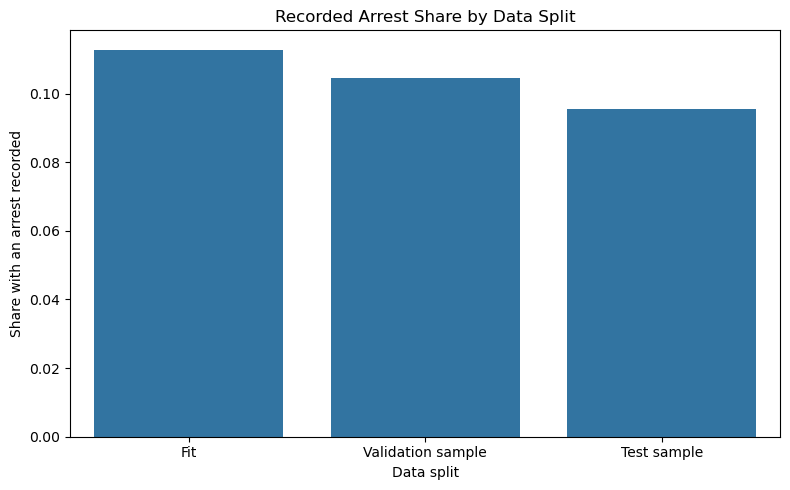

In [7]:
# compare arrest shares to show how the outcome mix changes over time
class_balance_df = pd.DataFrame({
    'split': ['Fit', 'Validation sample', 'Test sample'],
    'arrest_rate': [y_fit.mean(), y_val_sample.mean(), y_test_sample.mean()]
})
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=class_balance_df, x='split', y='arrest_rate', ax=ax)
ax.set_title('Recorded Arrest Share by Data Split')
ax.set_xlabel('Data split')
ax.set_ylabel('Share with an arrest recorded')
plt.tight_layout()
plt.savefig('../images/model_class_balance.png', dpi=150)
plt.show()

## Chronological cross-validation

Three expanding-window folds use a 120,000-row fit-period sample, sorted by date. Each validation window follows its training rows, and a calendar date is never split across folds. Grid search uses mean accuracy as in the course examples; the separate validation period selects thresholds and the preferred model using recall at the precision target.

In [8]:
# sample only the fitting period and restore chronological order
cv_sample = X_fit.sample(
    n=min(120000, len(X_fit)), random_state=42).sort_index()
y_cv = y_fit.loc[cv_sample.index]
cv_dates = train_df.loc[cv_sample.index, 'DATE OCC'].reset_index(drop=True)
cv_date_values = cv_dates.unique()
cv_block_size = len(cv_date_values) // 4
cv_splits = []
cv_fold_rows = []

# expand the training window and keep each calendar day together
for fold in range(3):
    train_date_end = cv_date_values[(fold + 1) * cv_block_size - 1]
    validation_date_end = cv_date_values[(fold + 2) * cv_block_size - 1]
    train_end = np.sum(cv_dates <= train_date_end)
    validation_end = np.sum(cv_dates <= validation_date_end)
    train_indices = np.arange(train_end)
    validation_indices = np.arange(train_end, validation_end)
    cv_splits.append((train_indices, validation_indices))
    # record boundaries so each later validation window can be checked
    cv_fold_rows.append({
        'fold': fold + 1,
        'fit_rows': len(train_indices),
        'validation_rows': len(validation_indices),
        'fit_through': train_date_end,
        'validation_start': cv_dates.iloc[train_end],
        'validation_end': validation_date_end
    })

cv_folds_df = pd.DataFrame(cv_fold_rows)
cv_folds_df

,fold,fit_rows,validation_rows,fit_through,validation_start,validation_end
0,1,29903,28933,2012-01-14,2012-01-15,2014-01-27
1,2,58836,27354,2014-01-27,2014-01-28,2016-02-10
2,3,86190,33810,2016-02-10,2016-02-11,2018-02-23


### Grid search for logistic regression and the decision tree

Grid search tunes a small set of model settings using the chronological folds. The later validation period remains separate for threshold selection and model comparison.

In [9]:
# fit scaling on each fold's training rows, never its validation rows
lgr_cv_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('lgr', LogisticRegression(
        class_weight='balanced', max_iter=1000, random_state=42))
])
lgr_params = {'lgr__C': [0.1, 1, 10]}
lgr_grid = GridSearchCV(
    lgr_cv_pipe, param_grid=lgr_params, cv=cv_splits,
    scoring='accuracy')
# the grid also refits the winning pipeline on the full CV sample
lgr_grid.fit(cv_sample, y_cv)

# tune the tree on the same chronological folds for comparison
tree_params = {
    'max_depth': [8, 15],
    'min_samples_leaf': [100, 300],
    'criterion': ['gini', 'entropy'],
    'class_weight': ['balanced']
}
tree_grid = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid=tree_params, cv=cv_splits, scoring='accuracy')
tree_grid.fit(cv_sample, y_cv)

# summarize tuning scores; final model choice uses later validation
cv_results_df = pd.DataFrame([
    {'model': 'Logistic regression',
     'mean_cv_accuracy': lgr_grid.best_score_},
    {'model': 'Decision tree',
     'mean_cv_accuracy': tree_grid.best_score_}
])
print(f'Logistic regression settings: {lgr_grid.best_params_}')
print(f'Decision tree settings: {tree_grid.best_params_}')
cv_results_df

Logistic regression settings: {'lgr__C': 10}
Decision tree settings: {'class_weight': 'balanced', 'criterion': 'gini', 'max_depth': 8, 'min_samples_leaf': 100}


,model,mean_cv_accuracy
0,Logistic regression,0.691226
1,Decision tree,0.677458


## Evaluation helpers

Because recorded arrests are uncommon, accuracy alone can hide missed arrests. Recall measures the share of recorded arrests identified; precision measures how often a predicted arrest is recorded. The validation threshold is the one with the highest recall while meeting the precision floor. Ties go to higher precision, then the higher threshold.

In [10]:
# report the same metrics so accuracy does not hide missed arrests
def get_metrics(y_true, preds, model_name):
    return {
        'model': model_name,
        'rows': len(y_true),
        'accuracy': accuracy_score(y_true, preds),
        'precision': precision_score(y_true, preds, zero_division=0),
        'recall': recall_score(y_true, preds, zero_division=0)
    }

In [11]:
# compare validation cutoffs to see the precision and recall tradeoff
def get_threshold_scores(y_true, probabilities, model_name):
    rows = []
    for threshold in np.arange(0.05, 0.96, 0.01):
        preds = (probabilities >= threshold).astype(int)
        rows.append({
            'model': model_name,
            'threshold': threshold,
            'precision': precision_score(y_true, preds, zero_division=0),
            'recall': recall_score(y_true, preds, zero_division=0)
        })
    return pd.DataFrame(rows)

In [12]:
# require the precision target before maximizing validation recall
def select_threshold(scores_df, precision_floor):
    candidates_df = scores_df.loc[
        scores_df['precision'] >= precision_floor
    ]
    if candidates_df.empty:
        raise ValueError('No validation threshold meets the precision floor.')
    # break recall ties by precision, then by the higher cutoff
    return candidates_df.sort_values(
        ['recall', 'precision', 'threshold'],
        ascending=[False, False, False]
    ).iloc[0]

## No-arrest reference

The reference always predicts no arrest. It shows why accuracy alone is not enough for these imbalanced labels.

In [13]:
# show what accuracy alone rewards when no arrests are predicted
baseline_preds = np.zeros(len(y_test_sample), dtype=int)
baseline_results = get_metrics(
    y_test_sample, baseline_preds, 'No-arrest reference')
baseline_results

{'model': 'No-arrest reference',
 'rows': 50000,
 'accuracy': 0.90462,
 'precision': 0.0,
 'recall': 0.0}

## Logistic regression

Balanced class weights help the model pay attention to the less common positive class. The regularization setting comes from chronological cross-validation. The final scaler and model are fit on the full fit period.

In [14]:
# refit the scaler and model on X_fit only, excluding validation
lgr_pipe = lgr_grid.best_estimator_
lgr_pipe.fit(X_fit, y_fit)
lgr_val_probabilities = lgr_pipe.predict_proba(X_val_sample)[:, 1]

In [15]:
# choose the cutoff on validation and carry it unchanged to test
precision_floor = 0.25
lgr_val_scores = get_threshold_scores(
    y_val_sample, lgr_val_probabilities, 'Logistic regression')
lgr_threshold = select_threshold(lgr_val_scores, precision_floor)
lgr_test_probabilities = lgr_pipe.predict_proba(X_test_sample)[:, 1]
lgr_preds = (
    lgr_test_probabilities >= lgr_threshold['threshold']
).astype(int)

## Decision tree

The tree settings come from chronological cross-validation. The selected tree is refit on a 300,000-row sample from the fit period; the separate validation period selects its probability threshold.

In [16]:
# limit tree fitting cost with a sample from the fitting period only
tree_sample = X_fit.sample(
    n=min(300000, len(X_fit)), random_state=42)
y_tree_sample = y_fit.loc[tree_sample.index]
best_tree = tree_grid.best_params_
tree_class_weight = best_tree['class_weight']
print(best_tree)

{'class_weight': 'balanced', 'criterion': 'gini', 'max_depth': 8, 'min_samples_leaf': 100}


In [17]:
print(f'Mean chronological CV accuracy: {tree_grid.best_score_:.3f}')

Mean chronological CV accuracy: 0.677


In [18]:
best_tree

{'class_weight': 'balanced',
 'criterion': 'gini',
 'max_depth': 8,
 'min_samples_leaf': 100}

In [19]:
# fit the selected tree settings before choosing a validation cutoff
dtree = DecisionTreeClassifier(
    max_depth=int(best_tree['max_depth']),
    min_samples_leaf=int(best_tree['min_samples_leaf']),
    criterion=best_tree['criterion'], class_weight=tree_class_weight,
    random_state=42)
dtree.fit(tree_sample, y_tree_sample)
dtree_val_probabilities = dtree.predict_proba(X_val_sample)[:, 1]
dtree_val_scores = get_threshold_scores(
    y_val_sample, dtree_val_probabilities, 'Decision tree')
dtree_threshold = select_threshold(dtree_val_scores, precision_floor)

In [20]:
# apply the validation cutoff without adjusting it to test outcomes
dtree_test_probabilities = dtree.predict_proba(X_test_sample)[:, 1]
dtree_preds = (
    dtree_test_probabilities >= dtree_threshold['threshold']
).astype(int)

### Decision-tree ablation

This comparison removes the multiple-offense flag and otherwise keeps the selected tree settings. It is a limited feature check. Like the other model comparisons, it describes associations, not causes.

In [21]:
# remove one input while keeping the tree settings and rows fixed
tree_sample_ablation = tree_sample.drop(
    'Multiple Offenses Flag', axis=1)
X_val_ablation = X_val_sample.drop('Multiple Offenses Flag', axis=1)
X_test_ablation = X_test_sample.drop('Multiple Offenses Flag', axis=1)
dtree_ablation = DecisionTreeClassifier(
    max_depth=int(best_tree['max_depth']),
    min_samples_leaf=int(best_tree['min_samples_leaf']),
    criterion=best_tree['criterion'], class_weight=tree_class_weight,
    random_state=42)
dtree_ablation.fit(tree_sample_ablation, y_tree_sample)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",8
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",100
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: dict, list of dict or ""balanced"", default=NoneWeights associated with classes in the form ``{class_label: weight}``.If None, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_fe

In [22]:
# give the reduced-input tree its own validation-selected cutoff
ablation_val_probabilities = dtree_ablation.predict_proba(
    X_val_ablation)[:, 1]
ablation_val_scores = get_threshold_scores(
    y_val_sample, ablation_val_probabilities, 'Tree without multiple-offense flag')
ablation_threshold = select_threshold(
    ablation_val_scores, precision_floor)
ablation_test_probabilities = dtree_ablation.predict_proba(
    X_test_ablation)[:, 1]
ablation_preds = (
    ablation_test_probabilities >= ablation_threshold['threshold']
).astype(int)

## K-nearest neighbors

KNN is fit on a 10,000-row sample because prediction compares each row with the stored training rows. The scaler is fit on that sample only.

In [23]:
# keep neighbor searches manageable with a smaller fitting sample
knn_fit = X_fit.sample(
    n=min(10000, len(X_fit)), random_state=42)
y_knn_fit = y_fit.loc[knn_fit.index]
knn_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier(n_neighbors=25))
])
# learn scaling from knn_fit only, not validation or test rows
knn_pipe.fit(knn_fit, y_knn_fit)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('knn', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](73,)","['Vict Age','Age Known','month',...,'hour_bin_Morning', 'hour_bin_Afternoon','hour_bin_Evening']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,73
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [24]:
# select the neighbor cutoff on validation before applying it to test
knn_val_probabilities = knn_pipe.predict_proba(X_val_sample)[:, 1]
knn_val_scores = get_threshold_scores(
    y_val_sample, knn_val_probabilities, 'K-nearest neighbors')
knn_threshold = select_threshold(knn_val_scores, precision_floor)
knn_test_probabilities = knn_pipe.predict_proba(X_test_sample)[:, 1]
knn_preds = (
    knn_test_probabilities >= knn_threshold['threshold']
).astype(int)

## Neural network

The network uses a balanced sample of the fit period. Validation and test data keep their natural class balance. The network and scaler see only the fit sample. Validation loss rises from the first epoch while training loss falls, which reflects the balanced fit sample against the natural class mix in validation; the threshold selection, not the loss, decides how the network is used.

In [49]:
# balance fitting outcomes so the network sees as many arrest records
nn_pos = y_fit[y_fit == 1]
nn_neg = y_fit[y_fit == 0].sample(
    n=len(nn_pos), random_state=42)
nn_fit = pd.concat([nn_pos, nn_neg])
X_nn_fit = X_fit.loc[nn_fit.index]
y_nn_fit = nn_fit
print(f'Balanced neural-network rows: {len(X_nn_fit):,}')

Balanced neural-network rows: 374,516


In [50]:
# learn scaling from the balanced fitting sample; reuse it unchanged
nn_scaler = StandardScaler()
X_nn_fit_scaled = nn_scaler.fit_transform(X_nn_fit)
X_nn_val_scaled = nn_scaler.transform(X_val_sample)
X_nn_test_scaled = nn_scaler.transform(X_test_sample)

In [51]:
tf.random.set_seed(42)
# combine incident inputs in a small network with an arrest score
model = keras.Sequential([
    keras.Input(shape=(X_nn_fit_scaled.shape[1],)),
    layers.Dense(64, activation='relu'),
    layers.Dense(32, activation='relu'),
    layers.Dense(16, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])
model.compile(optimizer='rmsprop', loss='binary_crossentropy',
              metrics=['accuracy'])

In [52]:
# stop when validation loss stalls to limit fitting past improvement
history = model.fit(
    X_nn_fit_scaled, y_nn_fit,
    validation_data=(X_nn_val_scaled, y_val_sample),
    epochs=20, batch_size=512, verbose=0,
    callbacks=[keras.callbacks.EarlyStopping(patience=2)])
print(f'Training stopped after {len(history.history["loss"])} epochs.')

Training stopped after 4 epochs.


In [53]:
# choose the network cutoff using the same validation precision target
nn_val_probabilities = np.asarray(
    model.predict(X_nn_val_scaled, verbose=0)).ravel()
nn_val_scores = get_threshold_scores(
    y_val_sample, nn_val_probabilities, 'Neural network')
nn_threshold = select_threshold(nn_val_scores, precision_floor)

In [54]:
# keep the network cutoff fixed when scoring the held-out records
nn_test_probabilities = np.asarray(
    model.predict(X_nn_test_scaled, verbose=0)).ravel()
nn_preds = (
    nn_test_probabilities >= nn_threshold['threshold']
).astype(int)

In [55]:
# collect each model's chosen cutoff and validation performance
validation_results_df = pd.DataFrame([
    {'model': 'Logistic regression', 'threshold': lgr_threshold['threshold'],
     'precision': lgr_threshold['precision'], 'recall': lgr_threshold['recall']},
    {'model': 'Decision tree', 'threshold': dtree_threshold['threshold'],
     'precision': dtree_threshold['precision'], 'recall': dtree_threshold['recall']},
    {'model': 'Tree without multiple-offense flag',
     'threshold': ablation_threshold['threshold'],
     'precision': ablation_threshold['precision'],
     'recall': ablation_threshold['recall']},
    # include the smaller-sample models under the same scoring rule
    {'model': 'K-nearest neighbors', 'threshold': knn_threshold['threshold'],
     'precision': knn_threshold['precision'], 'recall': knn_threshold['recall']},
    {'model': 'Neural network', 'threshold': nn_threshold['threshold'],
     'precision': nn_threshold['precision'], 'recall': nn_threshold['recall']}
])
validation_results_df

,model,threshold,precision,recall
0,Logistic regression,0.65,0.255262,0.457716
1,Decision tree,0.65,0.252510,0.468705
2,Tree without multiple-offense flag,0.64,0.250142,0.421405
3,K-nearest neighbors,0.31,0.254525,0.107501
4,Neural network,0.64,0.251926,0.515528


In [56]:
# select by validation recall among models meeting the precision floor
eligible_models_df = validation_results_df.loc[
    validation_results_df['precision'] >= precision_floor]
assert not eligible_models_df.empty, 'No model meets the precision target'
preferred_row = eligible_models_df.sort_values(
    ['recall', 'precision'], ascending=[False, False]
).iloc[0]
preferred_model = preferred_row['model']
print(f'Validation-selected model: {preferred_model}')

Validation-selected model: Neural network


In [57]:
# retain the cutoff curves to explain the selected model's tradeoff
validation_thresholds_df = pd.concat([
    lgr_val_scores, dtree_val_scores, ablation_val_scores,
    knn_val_scores, nn_val_scores
], ignore_index=True)
validation_thresholds_df.head()

,model,threshold,precision,recall
0,Logistic regression,0.05,0.104650,1.0
1,Logistic regression,0.06,0.104666,1.0
2,Logistic regression,0.07,0.104671,1.0
3,Logistic regression,0.08,0.104681,1.0
4,Logistic regression,0.09,0.104739,1.0


## Final test comparison

All models use the same random sample of the future test period. These results are not used for tuning or model selection in this comparison. The period was examined in the earlier baseline, so it is not a pristine final holdout.

In [34]:
# keep predictions aligned to the same test rows for all models
test_predictions = {
    'No-arrest reference': baseline_preds,
    'Logistic regression': lgr_preds,
    'Decision tree': dtree_preds,
    'Tree without multiple-offense flag': ablation_preds,
    'K-nearest neighbors': knn_preds,
    'Neural network': nn_preds
}
# retain the validation cutoffs so the test table documents each rule
model_thresholds = {
    'Logistic regression': lgr_threshold['threshold'],
    'Decision tree': dtree_threshold['threshold'],
    'Tree without multiple-offense flag': ablation_threshold['threshold'],
    'K-nearest neighbors': knn_threshold['threshold'],
    'Neural network': nn_threshold['threshold']
}

In [35]:
# show fitting sizes because the models used different sample sizes
fit_rows = {
    'No-arrest reference': 0,
    'Logistic regression': len(X_fit),
    'Decision tree': len(tree_sample),
    'Tree without multiple-offense flag': len(tree_sample),
    'K-nearest neighbors': len(knn_fit),
    'Neural network': len(X_nn_fit)
}
results_rows = []
# score each fixed prediction set without selecting again on test
for model_name, preds in test_predictions.items():
    row = get_metrics(y_test_sample, preds, model_name)
    row['fit_rows'] = fit_rows[model_name]
    row['threshold'] = model_thresholds.get(model_name, np.nan)
    results_rows.append(row)
results_df = pd.DataFrame(results_rows)
results_df

,model,rows,accuracy,precision,recall,fit_rows,threshold
0,No-arrest reference,50000,0.90462,0.000000,0.000000,0,NaN
1,Logistic regression,50000,0.80802,0.246961,0.494234,1660234,0.65
2,Decision tree,50000,0.80490,0.247672,0.513105,300000,0.65
3,Tree without multiple-offense flag,50000,0.80386,0.231335,0.454812,300000,0.64
4,K-nearest neighbors,50000,0.88238,0.258890,0.125183,10000,0.31
5,Neural network,50000,0.79460,0.244970,0.553995,374516,0.64


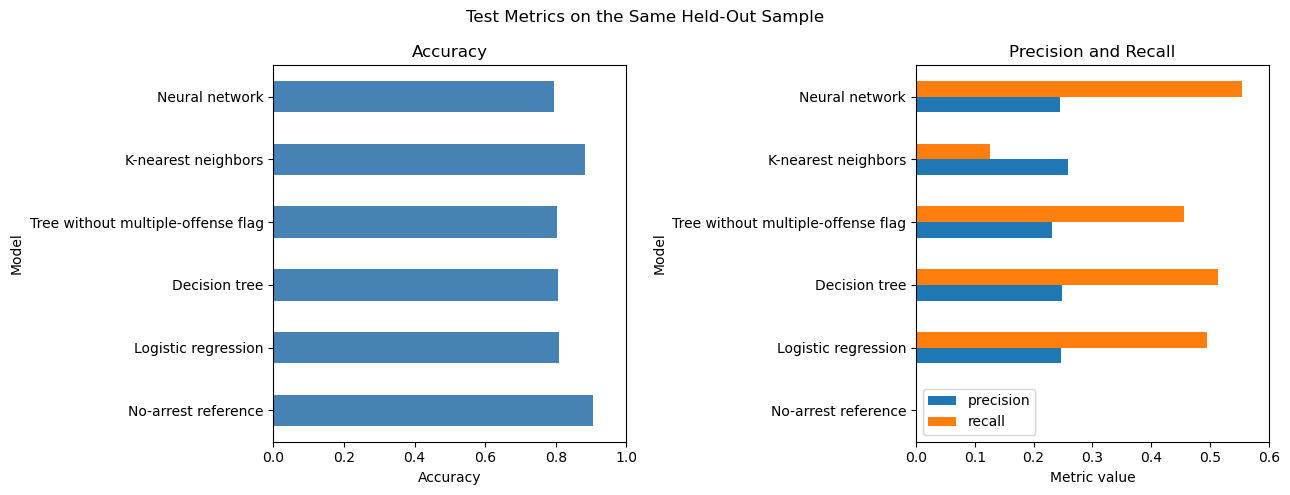

In [36]:
# separate accuracy from arrest-focused metrics for readable scales
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
results_df.set_index('model')['accuracy'].plot(
    kind='barh', ax=ax[0], color='steelblue')
results_df.set_index('model')[['precision', 'recall']].plot(
    kind='barh', ax=ax[1])
ax[0].set_title('Accuracy')
ax[0].set_xlabel('Accuracy')
ax[0].set_ylabel('Model')
ax[0].set_xlim(0, 1)
# keep precision and recall together to show their tradeoff
ax[1].set_title('Precision and Recall')
ax[1].set_xlabel('Metric value')
ax[1].set_ylabel('Model')
ax[1].set_xlim(0, 0.6)
fig.suptitle('Test Metrics on the Same Held-Out Sample')
plt.tight_layout()
plt.savefig('../images/model_test_metrics.png', dpi=150)
plt.show()

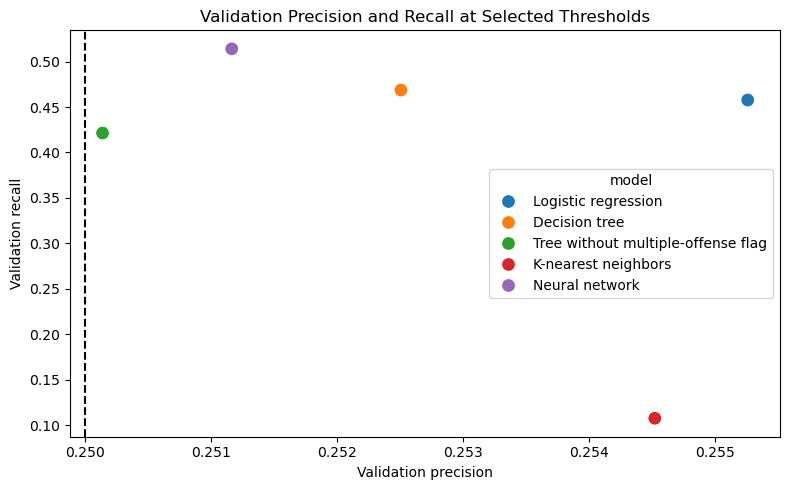

In [37]:
fig, ax = plt.subplots(figsize=(8, 5))
# compare chosen validation scores against the required precision
sns.scatterplot(
    data=validation_results_df, x='precision', y='recall',
    hue='model', s=100, ax=ax)
ax.axvline(precision_floor, color='black', linestyle='--')
ax.set_title('Validation Precision and Recall at Selected Thresholds')
ax.set_xlabel('Validation precision')
ax.set_ylabel('Validation recall')
plt.tight_layout()
plt.savefig('../images/model_validation_precision_recall.png', dpi=150)
plt.show()

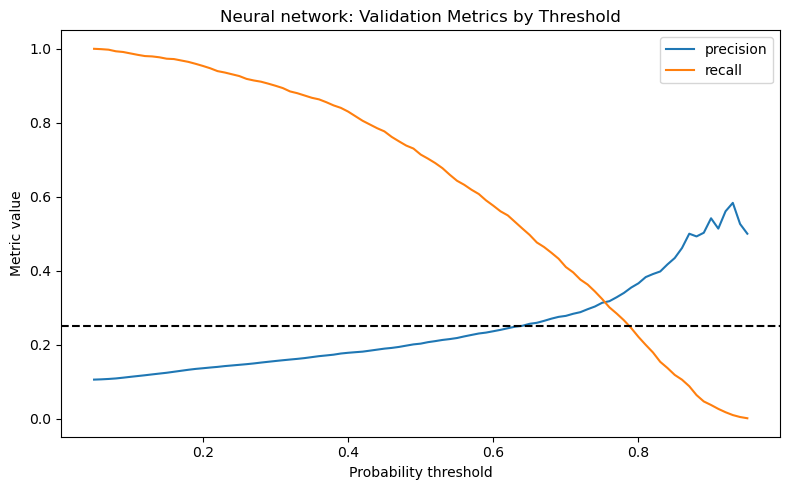

In [38]:
# show how changing the selected model's cutoff changes both metrics
preferred_thresholds_df = validation_thresholds_df.loc[
    validation_thresholds_df['model'] == preferred_model]
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(preferred_thresholds_df['threshold'],
        preferred_thresholds_df['precision'], label='precision')
ax.plot(preferred_thresholds_df['threshold'],
        preferred_thresholds_df['recall'], label='recall')
# mark the precision floor used during validation selection
ax.axhline(precision_floor, color='black', linestyle='--')
ax.set_title(f'{preferred_model}: Validation Metrics by Threshold')
ax.set_xlabel('Probability threshold')
ax.set_ylabel('Metric value')
ax.legend()
plt.tight_layout()
plt.savefig('../images/model_validation_thresholds.png', dpi=150)
plt.show()

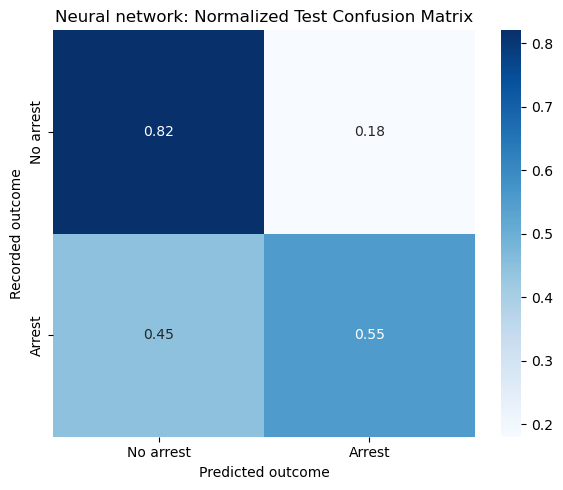

In [39]:
# normalize within recorded outcomes to make missed arrests visible
preferred_preds = test_predictions[preferred_model]
confusion = confusion_matrix(
    y_test_sample, preferred_preds, normalize='true')
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(confusion, annot=True, fmt='.2f', cmap='Blues', ax=ax,
            xticklabels=['No arrest', 'Arrest'],
            yticklabels=['No arrest', 'Arrest'])
ax.set_title(f'{preferred_model}: Normalized Test Confusion Matrix')
ax.set_xlabel('Predicted outcome')
ax.set_ylabel('Recorded outcome')
plt.tight_layout()
plt.savefig('../images/model_test_confusion_matrix.png', dpi=150)
plt.show()

In [40]:
# pair the selected model's scores with recorded outcomes for plotting
test_probabilities = {
    'Logistic regression': lgr_test_probabilities,
    'Decision tree': dtree_test_probabilities,
    'Tree without multiple-offense flag': ablation_test_probabilities,
    'K-nearest neighbors': knn_test_probabilities,
    'Neural network': nn_test_probabilities
}
probability_df = pd.DataFrame({
    'probability': test_probabilities[preferred_model],
    'Arrested': y_test_sample.to_numpy()
})

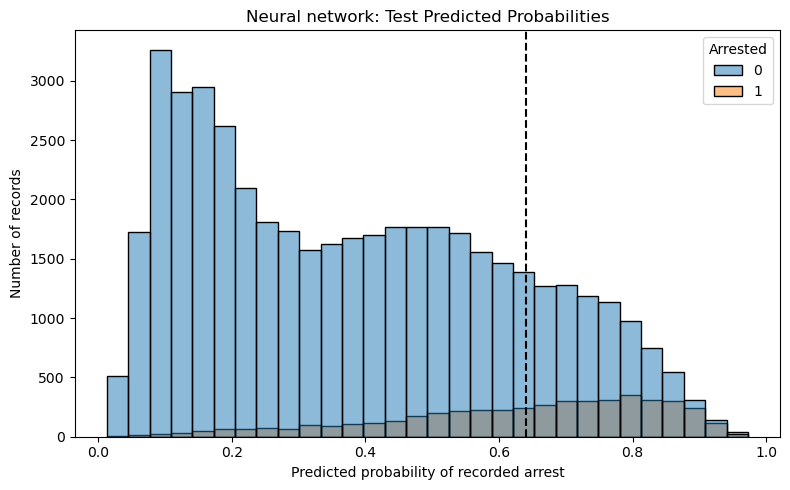

In [41]:
fig, ax = plt.subplots(figsize=(8, 5))
# show score overlap to make false alarms and missed arrests visible
sns.histplot(data=probability_df, x='probability', hue='Arrested',
             bins=30, ax=ax)
ax.axvline(model_thresholds[preferred_model], color='black',
           linestyle='--', label='validation threshold')
ax.set_title(f'{preferred_model}: Test Predicted Probabilities')
ax.set_xlabel('Predicted probability of recorded arrest')
ax.set_ylabel('Number of records')
plt.tight_layout()
plt.savefig('../images/model_test_probabilities.png', dpi=150)
plt.show()

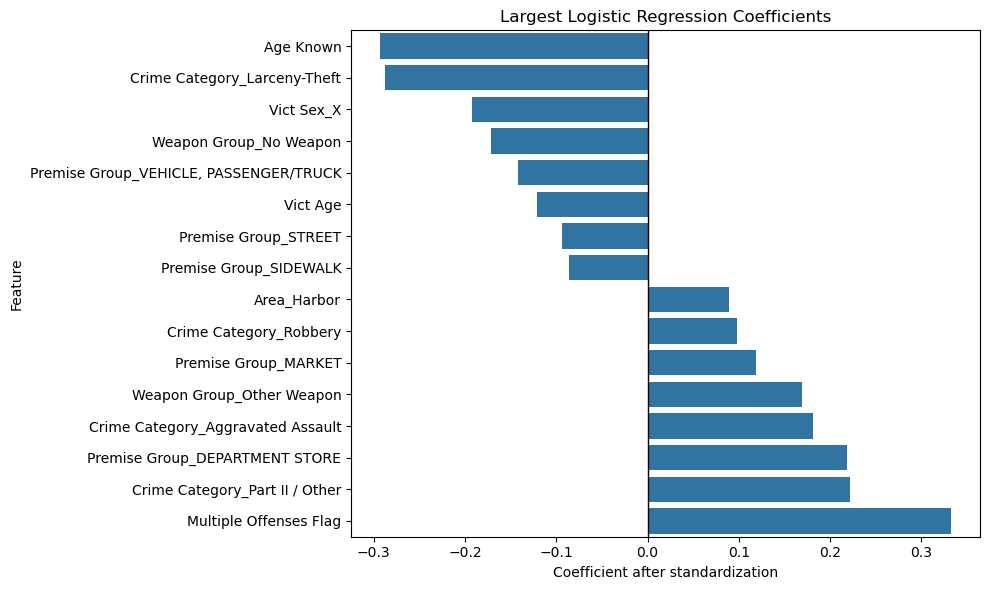

In [42]:
# inspect strong fitted associations, not causes of recorded arrests
coef_df = pd.DataFrame({
    'feature': X_fit.columns,
    'coefficient': lgr_pipe.named_steps['lgr'].coef_[0]
}).sort_values('coefficient')
top_coef_df = pd.concat([coef_df.head(8), coef_df.tail(8)])
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=top_coef_df, x='coefficient', y='feature', ax=ax)
# use zero as the reference for positive and negative coefficients
ax.axvline(0, color='black', linewidth=1)
ax.set_title('Largest Logistic Regression Coefficients')
ax.set_xlabel('Coefficient after standardization')
ax.set_ylabel('Feature')
plt.tight_layout()
plt.savefig('../images/model_logistic_coefficients.png', dpi=150)
plt.show()

## Demographic subgroup check

This check reports test metrics for victim sex and victim descent categories for the model selected on validation data. Groups with small counts can have unstable metrics. These fields describe victims, not offender characteristics. The check is descriptive, not a fairness certification. Model scores and subgroup differences are not evidence for individual policing decisions.

In [43]:
# check victim indicators before comparing groups on the test sample
group_columns = {
    'Victim sex': ['Vict Sex_F', 'Vict Sex_M', 'Vict Sex_X'],
    'Victim descent': [
        'Vict Descent_Am Indian/Alaskan', 'Vict Descent_Asian/PI',
        'Vict Descent_Black', 'Vict Descent_Hispanic',
        'Vict Descent_Other', 'Vict Descent_Unknown',
        'Vict Descent_White'
    ]
}
assert all(column in X_test_sample.columns
           for columns in group_columns.values() for column in columns)

In [44]:
# reuse the selected model's predictions; do not refit for each group
group_rows = []
for group_type, columns in group_columns.items():
    for column in columns:
        mask = X_test_sample[column] == 1
        group_y = y_test_sample.loc[mask]
        group_preds = preferred_preds[mask.to_numpy()]
        group_metrics = get_metrics(group_y, group_preds, column)
        # retain counts because scores for small groups can be unstable
        group_rows.append({
            'group_type': group_type,
            'group': column.replace('Vict Sex_', '').replace(
    'Vict Descent_', ''),
            'rows': len(group_y),
            'recorded_arrests': int(group_y.sum()),
            'precision': group_metrics['precision'],
            'recall': group_metrics['recall'],
            'accuracy': group_metrics['accuracy']
        })

In [45]:
# keep the group type in labels so the comparisons remain distinct
subgroup_results_df = pd.DataFrame(group_rows)
subgroup_results_df['label'] = (
    subgroup_results_df['group_type'] + ': ' + subgroup_results_df['group'])
subgroup_results_df

,group_type,group,rows,recorded_arrests,precision,recall,accuracy,label
0,Victim sex,F,18149,1892,0.233130,0.626321,0.746267,Victim sex: F
1,Victim sex,M,20579,2026,0.255367,0.563672,0.795228,Victim sex: M
2,Victim sex,X,11272,851,0.256098,0.370153,0.871274,Victim sex: X
3,Victim descent,Am Indian/Alaskan,52,2,0.000000,0.000000,0.961538,Victim descent: Am Indian/Alaskan
4,Victim descent,Asian/PI,1982,118,0.250000,0.500000,0.880928,Victim descent: Asian/PI
5,Victim descent,Black,7039,635,0.234027,0.513386,0.804518,Victim descent: Black
6,Victim descent,Hispanic,15020,1890,0.241478,0.670899,0.693409,Victim descent: Hispanic
7,Victim descent,Other,4045,417,0.262500,0.553957,0.793572,Victim descent: Other
8,Victim descent,Unknown,11756,932,0.261606,0.380901,0.865686,Victim descent: Unknown
9,Victim descent,White,10106,775,0.241607,0.520000,0.838017,Victim descent: White


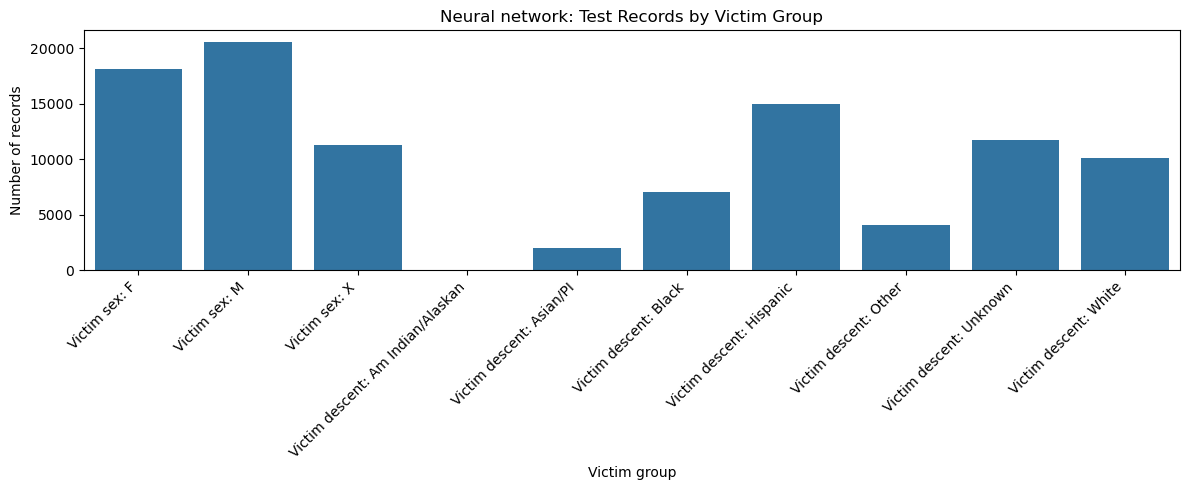

In [46]:
fig, ax = plt.subplots(figsize=(12, 5))
# show group sizes alongside the later recall comparison
sns.barplot(data=subgroup_results_df, x='label', y='rows', ax=ax)
ax.set_title(f'{preferred_model}: Test Records by Victim Group')
ax.set_xlabel('Victim group')
ax.set_ylabel('Number of records')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('../images/model_subgroup_counts.png', dpi=150)
plt.show()

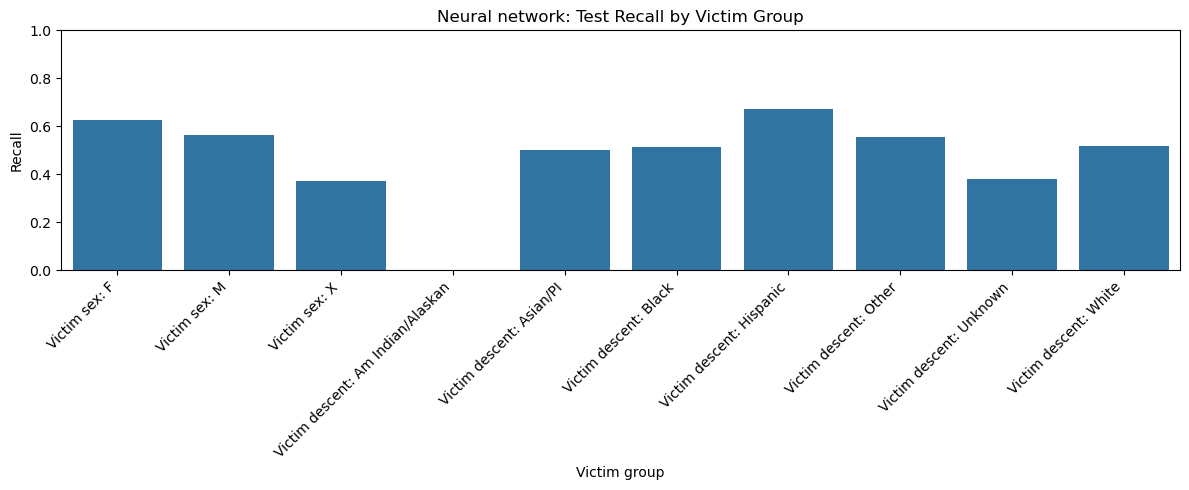

In [47]:
fig, ax = plt.subplots(figsize=(12, 5))
# compare captured arrests by victim group, not individual risk
sns.barplot(data=subgroup_results_df, x='label', y='recall', ax=ax)
ax.set_title(f'{preferred_model}: Test Recall by Victim Group')
ax.set_xlabel('Victim group')
ax.set_ylabel('Recall')
ax.set_ylim(0, 1)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('../images/model_subgroup_recall.png', dpi=150)
plt.show()

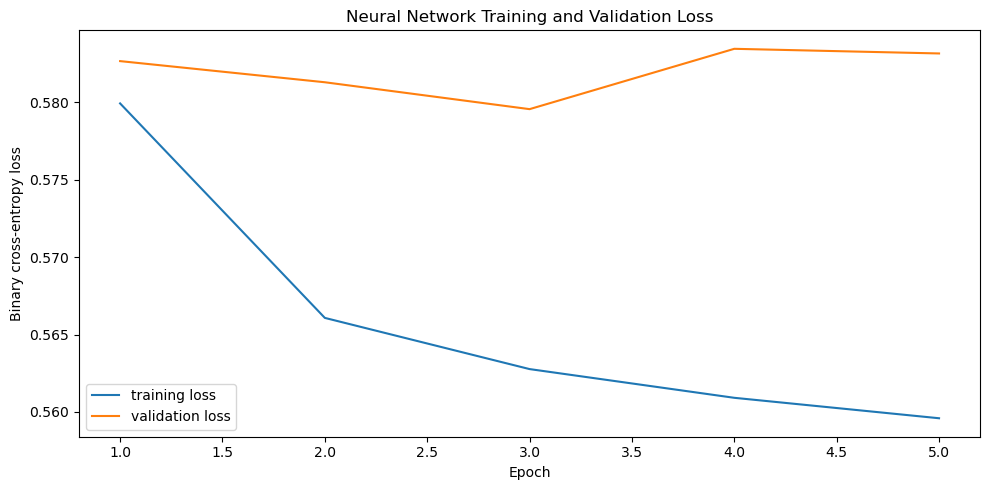

In [48]:
fig, ax = plt.subplots(figsize=(10, 5))
# compare fitting and validation loss to inspect signs of overfitting
epochs = range(1, len(history.history['loss']) + 1)
ax.plot(epochs, history.history['loss'], label='training loss')
ax.plot(epochs, history.history['val_loss'], label='validation loss')
ax.set_title('Neural Network Training and Validation Loss')
ax.set_xlabel('Epoch')
ax.set_ylabel('Binary cross-entropy loss')
ax.legend()
plt.tight_layout()
plt.savefig('../images/model_neural_network_loss.png', dpi=150)
plt.show()

## Interpretation and limitations

The final table reports every candidate on the same random test sample. The model choice and thresholds were fixed using validation data. The test sample is only part of the held-out period, and its scores may vary with the random sample.

A recorded arrest is a status in this data snapshot. Case status can change, and the 2024 data cover only two months.